# 29 XGBoost: Fehlerart und Handlungsklasse je Station

Teil 6: Lernende Modelle

**Worum es geht**
- Die Notebooks 25 bis 28 liefern je eine Sicht auf die Stationen: Kennzahlen, ein gelerntes LSTM-Embedding (Embedding = kurze Zahlenreihe, die das Verhalten einer Station zusammenfasst), die Abweichungen des Wächters.
- Hier fließen alle in ein Modell je Fehlerart. Erste Frage: Welche Fehlerarten lassen sich aus den Daten vor der Begehung erkennen?
- Zweite Frage: Bringen Baum-Modelle (Random Forest, XGBoost) und Wechselwirkungen zwischen Merkmalen mehr als eine logistische Regression?
- Dritte Frage: Welche der drei Klassen aus Folie 5 bekommt jede der 91 Stationen mit Kennzahlen, auch die nie begangenen?

**Daten**
- liest: `modell_kennzahlen.csv`, `modell_labels.csv` (Notebook 25), `kmeans_einstufung.csv` (Notebook 26), `lstm_embedding.csv` (Notebook 27), `prognose_tage.csv` (Notebook 28), `hast_features.csv` (nur Anschlusswert)
- schreibt: `fehlerklassen_je_hast.csv` (Klasse nach Folie 5 und Hinweise je Zähler)
- vorher ausführen: Notebook 25, 26, 27, 28

## 1 Was vorher versucht wurde

- Dieses Notebook ist der letzte Schritt einer längeren Suche.
- Die Tabelle hält fest, was schon probiert wurde, damit es niemand wiederholt.

| Versuch | Ergebnis | Warum nicht übernommen |
|---|---|---|
| Ein Label „Maßnahme ja/nein“ für alle Fehler (`src/ml_classifier.py`) | trifft auf 40 von 49 Stationen zu; ML schlägt die Baseline nicht | zu grob; hier deshalb ein Modell je Fehlerart |
| Klassenausgleich: Over-, Undersampling, SMOTE (Vorarbeit, logistische Regression) | Ventil 0,91 bis 0,92 mit Ausgleich, 0,92 ohne; Temperatur mit Undersampling 0,19 schlechter; mittlere Ventil-Wahrscheinlichkeit 16 % ohne, 26 bis 36 % mit (tatsächlich 17 %) | ändert die Reihenfolge nicht, verzerrt aber die Wahrscheinlichkeiten; hier nur Kurztest (Abschnitt 8) |
| Graph-Netz über den Leitungsgraphen (Embedding + Nachbarn) | Ventil 0,89, Dämmung 0,66; ohne Kanten nicht schlechter | die Fehler sitzen im einzelnen Haus, nicht im Netz |
| Gebäudedaten aus dem Protokoll (Baujahr, Wohnfläche, Zusatzheizung) | Baujahr in 17, Wohnfläche in 28 von 66 Begehungen | zu lückenhaft, nur für begangene Stationen bekannt |
| XGBoost für die Überdimensionierung (Vorarbeit) | AUC 0,87 [0,71; 0,99] mit Straßen ausgelassen, damals bestes Verfahren | wird hier nachgeprüft: Bezug war im ersten Team-Lauf der Anschlusswert, und der ist teilweise schon der neue Wert (Notebook 25) |

## 2 Setup

- Lädt die drei Modellfamilien: logistische Regression, Random Forest (scikit-learn) und XGBoost (Gradient Boosting = viele kleine Entscheidungsbäume, jeder korrigiert die Fehler der vorigen).

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"
SEED = 0
print(f"XGBoost {xgboost.__version__}")

XGBoost 3.4.1


Was die Zelle macht:
- Importiert Bibliotheken und legt den Datenordner fest. Ausgabe: verwendete XGBoost-Version.

## 3 Eine Tabelle mit allen Merkmalen

- Je Zähler eine Zeile, drei Gruppen von Spalten: Kennzahlen, LSTM-Embedding, Wächter.
- Vom Wächter zählen nur Tage vor der Begehung, die er nicht zum Lernen benutzt hat (Validierung und Sommer 2024).

In [2]:
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler").drop(columns=["stunden_winter", "stunden_sommer"])
emb = pd.read_csv(PROCESSED / "lstm_embedding.csv", index_col="zaehler").filter(regex="lstm_(w2324|s2024)_")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
kmeans = pd.read_csv(PROCESSED / "kmeans_einstufung.csv", index_col="zaehler")
prog = pd.read_csv(PROCESSED / "prognose_tage.csv", parse_dates=["tag"])

vorher = prog[prog["abschnitt"].isin(["Validierung", "Test (Sommer 2024)"])].copy()
vorher["auffaellig"] = (vorher["z_rl"].abs() >= 3) | (vorher["z_fluss"].abs() >= 3)
waechter = vorher.groupby("zaehler").agg(
    waechter_res_rl=("res_rl", "mean"),
    waechter_res_fluss_nacht=("res_fluss_nacht", "mean"),
    waechter_anteil_auffaellig=("auffaellig", "mean"))

merkmale = kz.join(emb).join(waechter)
KENNZAHLEN = [c for c in kz.columns if c != "auslastung_vertrag"]      #wie NB 27
GRUPPEN = {
    "Kennzahlen (Notebook 18)": KENNZAHLEN,
    "LSTM-Embedding (Notebook 20)": list(emb.columns),
    "Wächter (Notebook 21)": list(waechter.columns),
}
print(f"merkmale: {merkmale.shape[0]} Zähler × {merkmale.shape[1]} Spalten")
pd.DataFrame({"Spalten": {g: len(s) for g, s in GRUPPEN.items()},
              "Zähler mit Werten": {g: int(merkmale[s].notna().all(axis=1).sum()) for g, s in GRUPPEN.items()}})

merkmale: 91 Zähler × 33 Spalten


,Spalten,Zähler mit Werten
Kennzahlen (Notebook 18),13,64
LSTM-Embedding (Notebook 20),16,79
Wächter (Notebook 21),3,87


In [3]:
merkmale.round(2).head()

,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,auslastung_vertrag,lstm_w2324_z0,lstm_w2324_z1,lstm_w2324_z2,lstm_w2324_z3,lstm_w2324_z4,lstm_w2324_z5,lstm_w2324_z6,lstm_w2324_z7,lstm_s2024_z0,lstm_s2024_z1,lstm_s2024_z2,lstm_s2024_z3,lstm_s2024_z4,lstm_s2024_z5,lstm_s2024_z6,lstm_s2024_z7,waechter_res_rl,waechter_res_fluss_nacht,waechter_anteil_auffaellig
zaehler,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
53198226,10.0,0.66,14.2,44.78,32.07,54.5,0.65,0.34,0.1,0.96,0.83,42.95,1.31,NaN,-0.06,0.12,-0.16,0.05,0.01,-0.34,-0.50,-1.18,-0.36,0.45,-0.32,-0.23,0.12,-0.16,0.36,-0.58,-0.04,-16.05,0.03
58177363,NaN,NaN,NaN,42.14,32.33,47.6,0.62,0.62,NaN,0.84,0.60,39.22,NaN,NaN,0.06,0.16,0.19,0.23,-0.15,-0.29,-0.40,-0.94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.61,-5.51,0.08
58177384,NaN,NaN,NaN,57.14,25.31,57.5,0.47,0.58,NaN,1.17,0.59,51.06,NaN,NaN,-0.12,0.09,-0.31,-0.28,-0.41,-0.42,-0.22,-0.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.83,47.06,0.04
58202380,NaN,NaN,NaN,56.75,NaN,68.2,NaN,1.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.67,1532.99,0.06
61620222,NaN,NaN,NaN,46.59,24.54,58.5,0.71,0.00,NaN,0.97,0.91,44.58,NaN,NaN,0.03,-0.03,0.17,0.37,0.04,-0.25,-0.05,0.11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.82,3.70,0.04


Was die beiden Zellen machen:
- Fügen die drei Quellen per Zählernummer zusammen: 13 Kennzahlen, 16 Embedding-Zahlen (Winter und Sommer), 3 Wächter-Merkmale.
- Dazu kommt `auslastung_vertrag`. Sie ist nur für begangene Zähler bekannt und wird nur bei der Überdimensionierung benutzt (Abschnitt 5).
- Fehlende Werte füllt später der Lernteil mit dem Median. XGBoost kommt mit Lücken selbst zurecht.
- Die Gruppennamen im Code tragen alte Nummern: Notebook 18 ist heute 25, Notebook 20 heute 27, Notebook 21 heute 28.

| Wächter-Merkmal | Bedeutung |
|---|---|
| `waechter_res_rl` | Wie viel wärmer kam der Rücklauf zurück als erwartet (Mittel, K)? |
| `waechter_res_fluss_nacht` | Wie viel mehr floss nachts als erwartet (l/h)? |
| `waechter_anteil_auffaellig` | Anteil der Tage mit einem z-Wert über 3 |

In [4]:
merkmale.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sommer_nachtfluss_lph,85.0,143.52,616.79,0.00,0.00,0.00,23.50,5165.00
sommer_durchlauf_anteil,85.0,0.36,0.38,0.00,0.06,0.16,0.71,1.00
sommer_nacht_spreizung_k,71.0,12.12,10.07,-14.70,2.55,12.00,18.60,35.70
winter_ruecklauf_bei_0c,88.0,47.26,9.89,28.48,41.98,46.20,53.20,68.99
winter_spreizung_last_k,89.0,25.12,8.36,4.02,20.61,27.43,30.57,39.80
winter_ruecklauf_p90,90.0,57.93,10.37,33.61,51.73,56.55,64.32,80.62
winter_fluss_cv,89.0,0.56,0.24,0.08,0.42,0.60,0.71,1.07
winter_nacht_tag_fluss,83.0,0.68,0.40,0.00,0.40,0.66,1.02,2.15
sommerlast_anteil,85.0,0.25,0.16,0.01,0.15,0.22,0.34,1.00
anteil_volumenstrom,88.0,0.82,0.36,-0.09,0.74,0.91,1.04,1.44


Was die Zelle macht:
- Zeigt je Spalte Anzahl, Mittel, Streuung und Spannweite. `count` = Zahl der Zähler mit Wert.
- Die Embedding-Zahlen sind standardisiert und liegen um 0. Wächter-Merkmale fehlen bei Zählern, die das LSTM nicht überwacht.

In [5]:
ZIELE = ["ventil", "daemmung", "ueberdimensioniert", "filter", "durchfluss", "temperatur"]
lesart = {1.0: "ja", 0.0: "nein"}
pd.DataFrame({ziel: labels[ziel].astype(float).map(lesart).fillna("unbekannt").value_counts() for ziel in ZIELE}).T.fillna(0).astype(int)[["ja", "nein", "unbekannt"]]

,ja,nein,unbekannt
ventil,11,45,0
daemmung,23,33,0
ueberdimensioniert,9,28,19
filter,26,30,0
durchfluss,20,36,0
temperatur,36,20,0


Was die Zelle macht:
- Zählt je Fehlerart, bei wie vielen begangenen Zählern der Befund ja, nein oder unbekannt ist.
- Unbekannt heißt: Das Protokoll gibt keine Antwort. Bei der Überdimensionierung fehlt dann die Vertragsleistung.
- Fehlerarten mit weniger als 5 Fällen oder Gegenfällen lassen sich nicht sinnvoll lernen.

## 4 Die Modelle

- Vier Modelltypen, von einfach bis mit Wechselwirkungen (Wechselwirkung = zwei Merkmale wirken nur gemeinsam, z. B. „hoher Rücklauf und wenig Spreizung“; Spreizung = Vorlauf minus Rücklauf).
- Der Vergleich XGBoost Tiefe 1 gegen Tiefe 2 bis 3 zeigt direkt, ob Wechselwirkungen etwas bringen. Alles andere ist gleich.
- Alle Modelle gewichten die seltene Klasse hoch. Bei XGBoost geschieht das über `scale_pos_weight`, neu berechnet in jedem Lernteil.
- Geprüft wird wie in Notebook 27 verschachtelt: Die Hyperparameter wählt eine innere 4-fache Kreuzvalidierung nur auf dem Lernteil.

| Modell | Entscheidung | Wechselwirkungen |
|---|---|---|
| Logistische Regression | gewichtete Summe der Merkmale | nein |
| Random Forest | Mehrheit aus 300 tiefen, zufällig variierten Bäumen | ja |
| XGBoost, Tiefe 1 | Summe vieler Bäume mit je einer Frage | nein, jeder Baum sieht nur ein Merkmal |
| XGBoost, Tiefe 2 bis 3 | Summe vieler Bäume mit 2 bis 3 Fragen hintereinander | ja |

In [6]:
class XGBAusgeglichen(XGBClassifier):
    def fit(self, X, y, **kwargs):
        self.set_params(scale_pos_weight=(len(y) - np.sum(y)) / max(np.sum(y), 1))
        return super().fit(X, y, **kwargs)


def modell(name):
    if name == "Logistische Regression":
        return (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(class_weight="balanced", max_iter=5000)),
                {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]})
    if name == "Random Forest":
        return (make_pipeline(SimpleImputer(strategy="median"),
                              RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=1)),
                {"randomforestclassifier__max_depth": [2, 4, None], "randomforestclassifier__min_samples_leaf": [2, 5]})
    tiefen = [1] if name == "XGBoost Tiefe 1" else [2, 3]
    return (XGBAusgeglichen(subsample=0.8, colsample_bytree=0.8, min_child_weight=2, n_jobs=1, random_state=SEED, verbosity=0),
            {"max_depth": tiefen, "learning_rate": [0.05, 0.15], "n_estimators": [100, 300]})


def verschachtelt(name, X, y, gruppen=None):
    schaetzer, raster = modell(name)
    suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
    aussen = LeaveOneOut() if gruppen is None else LeaveOneGroupOut()
    return cross_val_predict(suche, X, y, cv=aussen, groups=gruppen, method="predict_proba", n_jobs=-1)[:, 1]


def auc_mit_intervall(y, score, n=2000):
    rng = np.random.default_rng(SEED)
    ziehungen = [roc_auc_score(y[i], score[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n)) if 0 < y[i].sum() < len(i)]
    return roc_auc_score(y, score), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def auc_differenz(y, a, b, n=2000):
    rng = np.random.default_rng(SEED)
    ziehungen = [roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n)) if 0 < y[i].sum() < len(i)]
    return roc_auc_score(y, a) - roc_auc_score(y, b), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def precision_at_k(y, score, k=10):
    return y[np.argsort(-score)[:k]].mean()

Was die Zelle macht:
- `XGBAusgeglichen` ist XGBoost mit einer Zeile mehr: Vor jedem Lernen wird das Gewicht der seltenen Klasse aus dem Lernteil berechnet (Anzahl Nein / Anzahl Ja).
- `modell()` liefert je Modell die Pipeline und das Raster der Hyperparameter.
- `verschachtelt()`, `auc_mit_intervall()`, `auc_differenz()` und `precision_at_k()` sind dieselben Werkzeuge wie in Notebook 27.

## 5 Alle Fehlerarten, alle Modelle

- Sechs Kombinationen aus Modell und Merkmalen je Fehlerart. Jede wird zweimal geprüft: einzelne Stationen ausgelassen (Leave-one-out) und ganze Straßen ausgelassen.
- Bezug ist die logistische Regression nur auf den Kennzahlen, also ohne neuronale Netze. Wo es eine Faustregel gibt, steht sie als „Regel ohne Lernen“ daneben: Ventil = Anteil der Sommernächte mit Durchfluss (wie in Notebook 27), Überdimensioniert = niedrige Auslastung (Spitzenlast / Vertragsleistung vor der Begehung).
- Für die Überdimensionierung ersetzt `auslastung_vertrag` in allen Merkmalssätzen `auslastung`. Der Anschlusswert aus `Nodes_Edges.ods` ist bei 7 der 9 verkleinerten Verträge schon der neue Wert (Notebook 25). Mit ihm sähen gerade die überdimensionierten Stationen normal ausgelastet aus.
- Prüfbasis wie in Notebook 27: begangene Zähler mit Winter-Embedding und Sommerwerten. Die Rechnung dauert einige Minuten.

In [7]:
MERKMALSSAETZE = {
    "nur Kennzahlen": KENNZAHLEN,
    "Kennzahlen + LSTM": KENNZAHLEN + GRUPPEN["LSTM-Embedding (Notebook 20)"],
    "alle Merkmale": [s for spalten in GRUPPEN.values() for s in spalten],
}
ALLE = MERKMALSSAETZE["alle Merkmale"]
KOMBIS = [
    ("Logistische Regression", "nur Kennzahlen"),
    ("Logistische Regression", "Kennzahlen + LSTM"),
    ("Logistische Regression", "alle Merkmale"),
    ("Random Forest", "alle Merkmale"),
    ("XGBoost Tiefe 1", "alle Merkmale"),
    ("XGBoost Tiefe 2–3", "alle Merkmale"),
]
REGELN = {"ventil": ("sommer_durchlauf_anteil", +1), "ueberdimensioniert": ("auslastung_vertrag", -1)}
SPLITS = {"Station ausgelassen": None, "Straße ausgelassen": "strasse_gruppe"}


def spalten_fuer(ziel, satz):
    spalten = MERKMALSSAETZE[satz]
    if ziel == "ueberdimensioniert":
        spalten = ["auslastung_vertrag" if c == "auslastung" else c for c in spalten]
    return spalten


daten = labels.join(merkmale, how="inner")
daten = daten.dropna(subset=[c for c in emb.columns if "w2324" in c] + ["sommer_durchlauf_anteil"])
print(f"Prüfbasis: {len(daten)} begangene Zähler (wie Notebook 20)")

scores, zeilen = {}, []
for ziel in ZIELE:
    d = daten.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    if min(y.sum(), len(y) - y.sum()) < 5:
        zeilen.append({"Ziel": ziel, "Modell": "nicht modellierbar", "n": len(y), "Fälle": int(y.sum())})
        continue
    for split, gruppe in SPLITS.items():
        gruppen = None if gruppe is None else d[gruppe].to_numpy()
        kandidaten = [(name, satz, None) for name, satz in KOMBIS]
        if ziel in REGELN:
            kandidaten.insert(0, ("Regel ohne Lernen", REGELN[ziel][0], REGELN[ziel]))
        for name, satz, regel in kandidaten:
            if regel:
                spalte, richtung = regel
                s = (richtung * d[spalte].fillna(d[spalte].median())).to_numpy()     #fehlender Wert = Median
            else:
                s = verschachtelt(name, d[spalten_fuer(ziel, satz)], y, gruppen)
            scores[(ziel, split, name, satz)] = s
            auc, unten, oben = auc_mit_intervall(y, s)
            zeilen.append({"Ziel": ziel, "Split": split, "Modell": name, "Merkmale": satz, "n": len(y), "Fälle": int(y.sum()),
                           "AUC": auc, "unten": unten, "oben": oben, "P@10": precision_at_k(y, s)})
ergebnis = pd.DataFrame(zeilen)
loo = ergebnis[ergebnis["Split"] == "Station ausgelassen"]
loo.round(2)

Prüfbasis: 53 begangene Zähler (wie Notebook 20)


,Ziel,Split,Modell,Merkmale,n,Fälle,AUC,unten,oben,P@10
0,ventil,Station ausgelassen,Regel ohne Lernen,sommer_durchlauf_anteil,53,11,0.85,0.68,0.98,0.7
1,ventil,Station ausgelassen,Logistische Regression,nur Kennzahlen,53,11,0.79,0.57,0.97,0.6
2,ventil,Station ausgelassen,Logistische Regression,Kennzahlen + LSTM,53,11,0.90,0.80,0.97,0.6
3,ventil,Station ausgelassen,Logistische Regression,alle Merkmale,53,11,0.87,0.75,0.97,0.7
4,ventil,Station ausgelassen,Random Forest,alle Merkmale,53,11,0.81,0.62,0.96,0.6
5,ventil,Station ausgelassen,XGBoost Tiefe 1,alle Merkmale,53,11,0.82,0.66,0.96,0.6
6,ventil,Station ausgelassen,XGBoost Tiefe 2–3,alle Merkmale,53,11,0.84,0.70,0.95,0.6
14,daemmung,Station ausgelassen,Logistische Regression,nur Kennzahlen,53,22,0.69,0.53,0.84,0.9
15,daemmung,Station ausgelassen,Logistische Regression,Kennzahlen + LSTM,53,22,0.76,0.61,0.89,0.8
16,daemmung,Station ausgelassen,Logistische Regression,alle Merkmale,53,22,0.75,0.58,0.90,1.0


Was die Zelle macht:
- Rechnet für jede Fehlerart mit mindestens 5 Fällen und 5 Gegenfällen alle Kombinationen und, falls vorhanden, die Regel. Die Regel sortiert die Stationen nur nach einer Kennzahl, ohne Lernen.
- Die Tabelle zeigt die Variante „Station ausgelassen“. `n` = begangene Zähler mit bekanntem Label, `Fälle` = davon mit Befund, P@10 = Treffer unter den 10 am höchsten bewerteten Stationen.

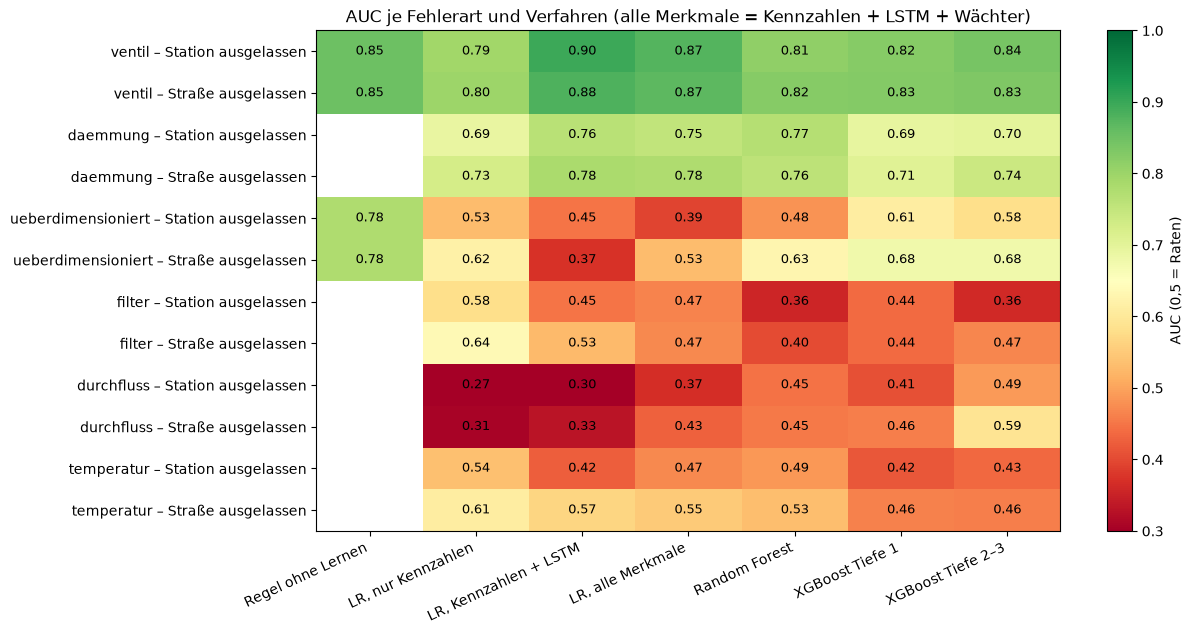

In [8]:
ergebnis["Verfahren"] = np.where(ergebnis["Modell"] == "Logistische Regression",
                                  "LR, " + ergebnis["Merkmale"].astype(str), ergebnis["Modell"])
spalten = ["Regel ohne Lernen", "LR, nur Kennzahlen", "LR, Kennzahlen + LSTM", "LR, alle Merkmale",
           "Random Forest", "XGBoost Tiefe 1", "XGBoost Tiefe 2–3"]
tafel = ergebnis.dropna(subset=["AUC"]).pivot_table(index=["Ziel", "Split"], columns="Verfahren", values="AUC")
tafel = tafel.reindex(columns=spalten).reindex(ZIELE, level=0)
fig, ax = plt.subplots(figsize=(12, 6.5))
bild = ax.imshow(tafel.to_numpy(dtype=float), cmap="RdYlGn", vmin=0.3, vmax=1.0, aspect="auto")
ax.set_xticks(range(tafel.shape[1]), tafel.columns, rotation=25, ha="right")
ax.set_yticks(range(tafel.shape[0]), [f"{z} – {s}" for z, s in tafel.index])
for i in range(tafel.shape[0]):
    for j in range(tafel.shape[1]):
        if pd.notna(tafel.iloc[i, j]):
            ax.text(j, i, f"{tafel.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(bild, label="AUC (0,5 = Raten)")
ax.set_title("AUC je Fehlerart und Verfahren (alle Merkmale = Kennzahlen + LSTM + Wächter)")
plt.show()

Was die Zelle macht:
- Fasst alle AUC-Werte in einem Bild zusammen (AUC = Wahrscheinlichkeit, dass eine Station mit Befund höher bewertet wird als eine ohne; 0,5 = Raten).
- Zeilen: Fehlerart und Art des Auslassens. Spalten: Verfahren. Grün ist gut, Gelb um 0,5 ist Raten. Leere Felder: keine Faustregel für diese Fehlerart.

**Ergebnis**

Drei Fehlerarten sind erkennbar:

| Fehlerart | bestes Verfahren | AUC Station | AUC Straße | P@10 |
|---|---|---|---|---|
| Ventil (11 von 53) | LR, Kennzahlen + LSTM | 0,89 [0,78; 0,97] | 0,83 | 7 von 10 |
| Dämmung (22 von 53) | LR, Kennzahlen + LSTM | 0,75 [0,59; 0,88] | 0,82 | 9 von 10 |
| Überdimensioniert (9 von 35) | Regel: niedrige Auslastung zum Vertrag vor der Begehung | 0,78 [0,53; 0,98] | 0,78 | 6 von 10 |

- Ventil: Die Sommernacht-Regel ohne Lernen ist fast gleich gut (0,85). Der Gewinn des LSTM liegt im Winter (Notebook 27).
- Überdimensionierung: Mit dem Anschlusswert als Bezug kam die Regel im ersten Team-Lauf auf 0,66 [0,37; 0,92], mit dem Vertrag vor der Begehung auf 0,78. Gelernte Modelle verwässern dieses Signal aus einer einzigen Zahl: logistische Regression 0,37 bis 0,53, Random Forest 0,53, XGBoost 0,72 bis 0,73 (Straßen ausgelassen 0,76 bis 0,78). XGBoost kommt der Regel am nächsten, erreicht aber weder 0,78 noch die 0,87 der Vorarbeit.
- Bei Ventil und Dämmung sind die Baum-Modelle nirgends besser als die logistische Regression (Random Forest 0,77 bzw. 0,71, XGBoost 0,69 bis 0,75 bzw. 0,67 bis 0,70). Die Wächter-Merkmale helfen nicht: Ventil 0,84 statt 0,89, Dämmung 0,72 statt 0,75. Der Wächter ist für neue Veränderungen gebaut, nicht für Dauerzustände.
- Nicht erkennbar sind Filter, Durchfluss und Temperatur: alle Verfahren zwischen 0,24 und 0,64, also im Bereich von Raten (siehe Zufallstest in Abschnitt 6.1). Wahrscheinlicher Grund laut Notebook 25: kaum ausdrückliche „nein“ bei Filter und Durchfluss, und die Temperatur wurde fast überall gesenkt.

## 6 Was ist belegt?

- Gepaarte Bootstrap-Differenzen der AUC (wie in Notebook 27) auf den Splits „Station ausgelassen“. Bootstrap = Stationen vielfach zufällig neu ziehen und die Differenz jedes Mal neu rechnen.
- Verglichen wird jedes Verfahren mit der logistischen Regression auf den Kennzahlen.
- Zusätzlich XGBoost mit Wechselwirkungen (Tiefe 2 bis 3) gegen ohne (Tiefe 1).

In [9]:
zeilen = []
split = "Station ausgelassen"
for ziel in ZIELE:
    if (ziel, split, "Logistische Regression", "nur Kennzahlen") not in scores:
        continue
    y = daten.dropna(subset=[ziel])[ziel].astype(int).to_numpy()
    bezug = scores[(ziel, split, "Logistische Regression", "nur Kennzahlen")]
    vergleiche = [(f"{n}, {s}" if n == "Logistische Regression" else n, scores[(ziel, split, n, s)], "LR, nur Kennzahlen", bezug)
                  for (z, sp, n, s) in scores if z == ziel and sp == split and s != "nur Kennzahlen"]
    vergleiche.append(("XGBoost Tiefe 2–3", scores[(ziel, split, "XGBoost Tiefe 2–3", "alle Merkmale")],
                       "XGBoost Tiefe 1", scores[(ziel, split, "XGBoost Tiefe 1", "alle Merkmale")]))
    for name, a, gegen, b in vergleiche:
        d, unten, oben = auc_differenz(y, a, b)
        zeilen.append({"Ziel": ziel, "Verfahren": name, "gegen": gegen, "Differenz": d, "unten": unten, "oben": oben,
                       "belegt": "besser" if unten > 0 else "schlechter" if oben < 0 else "–"})
differenzen = pd.DataFrame(zeilen)
differenzen.round(2)

,Ziel,Verfahren,gegen,Differenz,unten,oben,belegt
0,ventil,Regel ohne Lernen,"LR, nur Kennzahlen",0.06,-0.02,0.15,–
1,ventil,"Logistische Regression, Kennzahlen + LSTM","LR, nur Kennzahlen",0.11,-0.02,0.28,–
2,ventil,"Logistische Regression, alle Merkmale","LR, nur Kennzahlen",0.08,-0.08,0.27,–
3,ventil,Random Forest,"LR, nur Kennzahlen",0.02,-0.08,0.14,–
4,ventil,XGBoost Tiefe 1,"LR, nur Kennzahlen",0.03,-0.12,0.20,–
5,ventil,XGBoost Tiefe 2–3,"LR, nur Kennzahlen",0.05,-0.07,0.19,–
6,ventil,XGBoost Tiefe 2–3,XGBoost Tiefe 1,0.02,-0.04,0.09,–
7,daemmung,"Logistische Regression, Kennzahlen + LSTM","LR, nur Kennzahlen",0.07,-0.05,0.22,–
8,daemmung,"Logistische Regression, alle Merkmale","LR, nur Kennzahlen",0.06,-0.07,0.21,–
9,daemmung,Random Forest,"LR, nur Kennzahlen",0.08,-0.07,0.23,–


Was die Zelle macht:
- Rechnet je Fehlerart die gepaarten Differenzen. „besser“ oder „schlechter“ steht nur, wenn das 95-%-Intervall die 0 ausschließt.

**Ergebnis**
- Bei Ventil und Dämmung ist kein Verfahren belegt besser als die logistische Regression auf den Kennzahlen. Am nächsten dran: Kennzahlen + LSTM mit +0,10 [−0,02; +0,25] beim Ventil und +0,06 [−0,07; +0,21] bei der Dämmung. Das passt zu Notebook 27.
- Bei der Überdimensionierung ist die Regel belegt besser: +0,25 [+0,03; +0,47]. XGBoost ist ebenfalls belegt besser als diese logistische Regression (+0,20 [0,00; 0,40] und +0,19 [0,01; 0,37]), bleibt aber unter der Regel.
- Wechselwirkungen bringen nichts: Tiefe 2 bis 3 liegt beim Ventil 0,05 über Tiefe 1 (Intervall bis knapp unter 0), bei Dämmung und Überdimensionierung gleichauf oder knapp darunter.
- Beim Filter sind Random Forest und XGBoost belegt schlechter (−0,18 bis −0,27). Alle Filter-Werte liegen aber auf Ratenniveau oder darunter (0,31 bis 0,58), der Unterschied hat keinen Nutzen.

### 6.1 Wie weit streut die AUC bei reinem Zufall?

- Einige AUCs liegen deutlich unter 0,5, besonders beim Durchfluss. Liegen die Modelle systematisch falsch herum?
- Gegenprobe: Die Durchfluss-Labels werden 20-mal zufällig vertauscht. Dann gibt es sicher keinen Zusammenhang. Jedes Mal läuft dieselbe verschachtelte Prüfung.

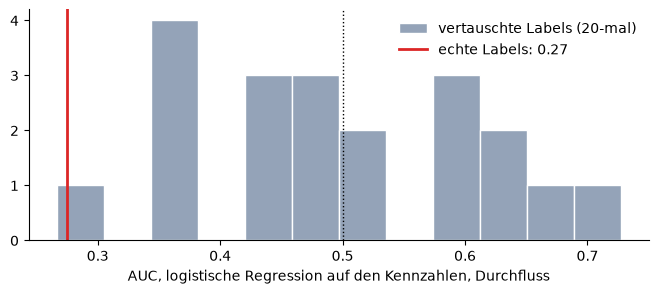

Vertauschte Labels: AUC im Mittel 0.50, Spanne 0.27 bis 0.73


In [10]:
d = daten.dropna(subset=["durchfluss"])
y_echt = d["durchfluss"].astype(int).to_numpy()
rng = np.random.default_rng(SEED)
zufall = [roc_auc_score(y_z, verschachtelt("Logistische Regression", d[KENNZAHLEN], y_z))
          for y_z in (rng.permutation(y_echt) for _ in range(20))]
echt = roc_auc_score(y_echt, scores[("durchfluss", split, "Logistische Regression", "nur Kennzahlen")])

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(zufall, bins=12, color="#94A3B8", edgecolor="white", label="vertauschte Labels (20-mal)")
ax.axvline(echt, color="#DC2626", lw=2, label=f"echte Labels: {echt:.2f}")
ax.axvline(0.5, color="black", ls=":", lw=1)
ax.set_xlabel("AUC, logistische Regression auf den Kennzahlen, Durchfluss")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"Vertauschte Labels: AUC im Mittel {np.mean(zufall):.2f}, Spanne {np.min(zufall):.2f} bis {np.max(zufall):.2f}")

Was die Zelle macht:
- Vertauscht die Labels zufällig (`rng.permutation`) und rechnet die Prüfung 20-mal.
- Das Histogramm zeigt die AUCs bei reinem Zufall, die rote Linie den Wert mit echten Labels.

**Ergebnis**
- Bei vertauschten Labels liegt die AUC im Mittel bei 0,50, streut aber von 0,27 bis 0,73. Jede vierte Ziehung liegt unter 0,4.
- Bei 53 Stationen sind Werte weit weg von 0,5 also auch ohne Zusammenhang normal. Darum steht hinter jeder AUC ein Intervall.
- Der echte Wert (0,27) liegt am unteren Rand: Nur eine der 20 Ziehungen kommt so tief. Das ist ein Hinweis auf einen schwachen umgekehrten Zusammenhang: Wo der Durchfluss eingestellt wurde, sahen die Kennzahlen vorher eher unauffällig aus. Vielleicht wurde gerade an gut laufenden Stationen nachgeregelt.
- Bei 6 Fehlerarten und 7 Verfahren ist ein einzelner Ausreißer dieser Größe nicht überraschend. Zur Erkennung taugt das nicht.

## 7 Worauf schaut XGBoost? SHAP-Werte und Wechselwirkungen

- SHAP-Werte zerlegen jede Vorhersage in Beiträge der Merkmale: Wie stark schiebt ein Merkmal die Vorhersage für eine Station nach oben oder unten? Der Mittelwert der Beträge ist die Wichtigkeit des Merkmals.
- XGBoost rechnet das selbst (`pred_contribs=True`), auch für Merkmalspaare (`pred_interactions=True`).
- Je Fehlerart wird ein XGBoost mit Tiefe 2 (damit Paare vorkommen können) auf allen begangenen Stationen gelernt. Das beschreibt das Modell, es prüft es nicht. Die Prüfung steht in Abschnitt 5.

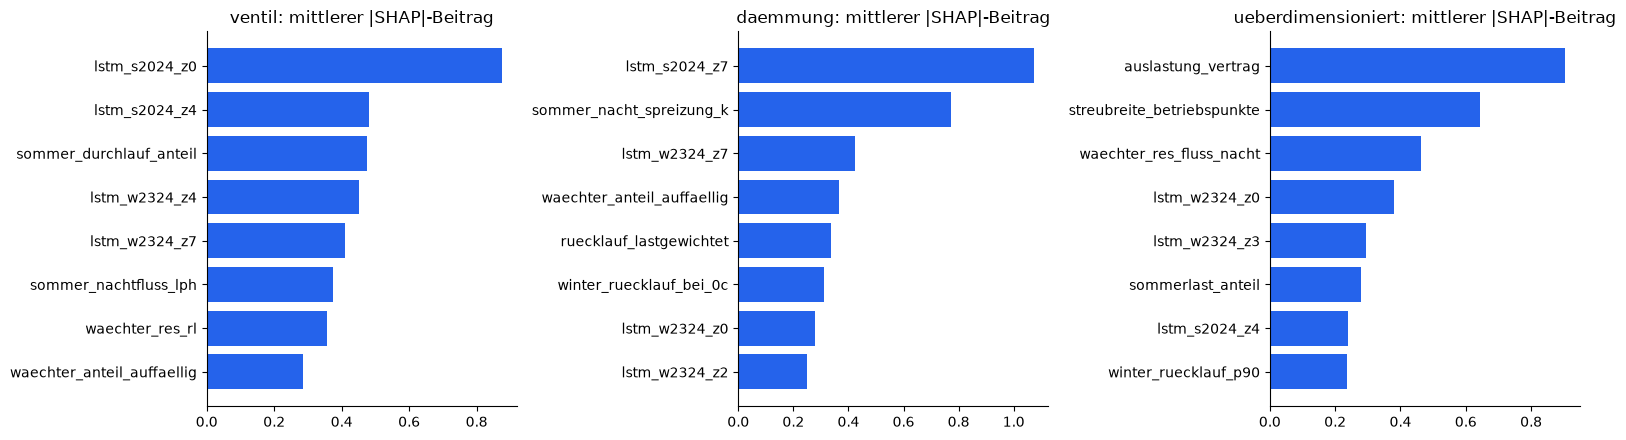

,Ziel,Merkmal A,Merkmal B,mittlerer |Beitrag| des Paares
0,ventil,lstm_s2024_z0,waechter_res_rl,0.060
1,ventil,sommer_nacht_spreizung_k,sommer_durchlauf_anteil,0.047
2,ventil,waechter_res_rl,lstm_s2024_z4,0.037
3,daemmung,lstm_s2024_z3,lstm_s2024_z7,0.114
4,daemmung,lstm_s2024_z7,waechter_anteil_auffaellig,0.081
5,daemmung,lstm_w2324_z2,sommer_nacht_spreizung_k,0.049
6,ueberdimensioniert,auslastung_vertrag,winter_ruecklauf_p90,0.058
7,ueberdimensioniert,auslastung_vertrag,lstm_w2324_z5,0.044
8,ueberdimensioniert,lstm_w2324_z3,streubreite_betriebspunkte,0.043


In [11]:
ERKLAEREN = ["ventil", "daemmung", "ueberdimensioniert"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
paare = []
for ax, ziel in zip(axes, ERKLAEREN):
    d = daten.dropna(subset=[ziel])
    spalten = spalten_fuer(ziel, "alle Merkmale")
    X, y = d[spalten], d[ziel].astype(int).to_numpy()
    xgb = XGBAusgeglichen(max_depth=2, learning_rate=0.05, n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                          min_child_weight=2, n_jobs=1, random_state=SEED, verbosity=0).fit(X, y)
    matrix = xgboost.DMatrix(X, missing=np.nan)
    beitraege = xgb.get_booster().predict(matrix, pred_contribs=True)[:, :-1]
    wichtig = pd.Series(np.abs(beitraege).mean(axis=0), index=spalten).sort_values().tail(8)
    ax.barh(wichtig.index, wichtig.values, color="#2563EB")
    ax.set_title(f"{ziel}: mittlerer |SHAP|-Beitrag")
    ax.spines[["top", "right"]].set_visible(False)

    inter = np.abs(xgb.get_booster().predict(matrix, pred_interactions=True)[:, :-1, :-1]).mean(axis=0)
    np.fill_diagonal(inter, 0)
    i, j = np.unravel_index(np.argsort(inter, axis=None)[::-1][:6:2], inter.shape)   #symmetrisch: jedes Paar steht zweimal
    for a, b in zip(i, j):
        paare.append({"Ziel": ziel, "Merkmal A": spalten[a], "Merkmal B": spalten[b], "mittlerer |Beitrag| des Paares": 2 * inter[a, b]})
fig.tight_layout()
plt.show()
pd.DataFrame(paare).round(3)

Was die Zelle macht:
- Die Balken zeigen je Fehlerart die acht wichtigsten Merkmale nach SHAP.
- Die Tabelle zeigt je Fehlerart die drei stärksten Paare: Was trägt das Zusammenspiel zweier Merkmale über ihre Einzelwirkung hinaus bei?

**Ergebnis**
- Ventil: Vorne liegen Nachtdurchfluss und Durchlaufanteil im Sommer, danach zwei Zahlen des Winter-Embeddings (`lstm_w2324_z5`, `lstm_w2324_z0`). Das LSTM hat das Ventilbild also auch aus Winterdaten gelernt. Das passt zu Notebook 27.
- Dämmung: Vorne liegt die Spreizung in Sommernächten. Das passt zur Physik: Ungedämmte Leitungen geben auch nachts Wärme ab, das wenige durchfließende Wasser kühlt ab, die Spreizung steigt, obwohl niemand heizt.
- Überdimensioniert: Vorne liegt `auslastung_vertrag`, danach die Abweichung des Wächters beim Nachtdurchfluss und die Streubreite der Betriebspunkte. Das Modell nutzt also dieselbe Zahl wie die Regel.
- Wechselwirkungen spielen eine Nebenrolle: Die stärksten Paare tragen im Mittel 0,05 bis 0,11 bei, die wichtigsten Einzelmerkmale 0,6 bis 1,0. Das passt zu Abschnitt 6.

## 8 Kurztest: Hilft eine andere Gewichtung der seltenen Klasse?

- Alle Modelle oben gewichten die seltene Klasse hoch. Ist das nötig?
- Verglichen wird die logistische Regression auf allen Merkmalen mit und ohne Gewichtung.
- Neben der AUC zählt der Brier-Score = mittlerer quadratischer Abstand zwischen vorhergesagter Wahrscheinlichkeit und tatsächlichem Befund (kleiner ist besser). Er zeigt, ob die Wahrscheinlichkeiten stimmen, nicht nur ihre Reihenfolge.

In [12]:
zeilen = []
for ziel in ("ventil", "daemmung"):
    d = daten.dropna(subset=[ziel])
    X, y = d[ALLE], d[ziel].astype(int).to_numpy()
    for gewicht in ("balanced", None):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(class_weight=gewicht, max_iter=5000))
        suche = GridSearchCV(pipe, {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]}, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
        p = cross_val_predict(suche, X, y, cv=LeaveOneOut(), method="predict_proba", n_jobs=-1)[:, 1]
        zeilen.append({"Ziel": ziel, "Gewichtung": "ausgeglichen" if gewicht else "keine", "AUC": roc_auc_score(y, p),
                       "Brier": brier_score_loss(y, p), "mittlere Wahrscheinlichkeit": p.mean(), "tatsächlicher Anteil": y.mean()})
pd.DataFrame(zeilen).round(3)

,Ziel,Gewichtung,AUC,Brier,mittlere Wahrscheinlichkeit,tatsächlicher Anteil
0,ventil,ausgeglichen,0.874,0.105,0.272,0.208
1,ventil,keine,0.870,0.101,0.178,0.208
2,daemmung,ausgeglichen,0.754,0.201,0.479,0.415
3,daemmung,keine,0.757,0.185,0.429,0.415


Was die Zelle macht:
- Rechnet die logistische Regression einmal mit `class_weight="balanced"` und einmal ohne, sonst gleich.
- Vergleicht die mittlere vorhergesagte Wahrscheinlichkeit mit dem tatsächlichen Anteil. Bei stimmigen Wahrscheinlichkeiten liegen beide nah beieinander.

**Ergebnis**
- Die Reihenfolge der Stationen ändert sich kaum: Ventil 0,84 mit gegen 0,85 ohne Gewichtung, Dämmung 0,72 gegen 0,70.
- Die Wahrscheinlichkeiten schon: Mit Gewichtung sagt das Modell beim Ventil im Mittel 35 % voraus, tatsächlich haben 21 % einen Befund. Ohne Gewichtung sind es 20 %, der Brier-Score ist besser (0,113 statt 0,136). Bei der Dämmung (42 % Befunde) ändert sich wenig (0,216 mit, 0,213 ohne).
- Negativbefund: Eine andere Gewichtung hilft bei diesen Daten nicht beim Finden. Die Vorarbeit zeigte dasselbe für Over-, Undersampling und SMOTE. Nur XGBoost brauchte dort die Gewichtung, sonst ignorierte es die seltene Klasse fast.
- Folge für Abschnitt 9: Die feste Ventil-Grenze 0,5 gilt für gewichtete Wahrscheinlichkeiten, die im Mittel zu hoch liegen. Sie ist eine Grenze auf der Rangfolge, keine „50 % Wahrscheinlichkeit für einen Ventilschaden“.

## 9 Die drei Klassen der Folie 5 für jede Station

- Reihenfolge wie in Notebook 26: (1) „Regelventil tauschen“, wenn das Ventil-Modell die Station über seiner Schwelle sieht; (2) sonst „Regelparameter optimieren“, wenn K-Means sie als „schlechter“ einstuft; (3) sonst „kein Handlungsbedarf“.
- Für das Ventil zählt das gelernte Verfahren mit der besten AUC aus Abschnitt 5, nicht die Sommernacht-Regel, denn die braucht Sommerdaten. Die Schwelle ist fest 0,5. Der Youden-Index (Punkt, an dem Trefferquote minus Fehlalarmquote am größten ist) sprang nach dem Neuaufbau der Datenbasis in Notebook 00 (93 statt 96 Zähler) von 0,54 auf 0,17, und die Klasse wuchs von 21 auf 57 Zähler bei gleicher AUC. Bei 11 Ventilfällen hat die Kurve mehrere fast gleich hohe Spitzen. Ein Ventiltausch heißt Technikereinsatz, deshalb zählt die Precision mehr, und eine feste Grenze ist stabiler.
- Begangene Stationen bekommen den Wert aus der Kreuzvalidierung, das Modell hat sie beim Lernen nie gesehen. Nie begangene bekommen den Wert eines Modells, das auf allen begangenen gelernt hat.
- Dazu Hinweise auf Dämmung und Überdimensionierung (Schwelle per Youden-Index), aber nur, wenn das beste Verfahren belegt besser als Raten ist (untere Grenze des AUC-Intervalls über 0,5).

In [13]:
def endmodell(ziel, nur_gelernt=False, schwelle_fest=None):
    t = loo[loo["Ziel"] == ziel]
    if nur_gelernt:
        t = t[t["Modell"] != "Regel ohne Lernen"]
    t = t.sort_values("AUC", ascending=False).iloc[0]
    d = daten.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    oof = pd.Series(scores[(ziel, split, t["Modell"], t["Merkmale"])], index=d.index)
    fpr, tpr, schwellen = roc_curve(y, oof)
    youden = schwellen[np.argmax(tpr - fpr)]
    schwelle = youden if schwelle_fest is None else schwelle_fest
    x_alle = merkmale.copy()
    if ziel == "ueberdimensioniert":
        #nie begangene haben kein Protokoll, für sie gilt der Anschlusswert als Vertrag
        x_alle["auslastung_vertrag"] = x_alle["auslastung_vertrag"].fillna(x_alle["auslastung"])
    if t["Modell"] == "Regel ohne Lernen":
        spalte, richtung = REGELN[ziel]
        wert = richtung * x_alle[spalte].fillna(daten[spalte].median())
    else:
        spalten = spalten_fuer(ziel, t["Merkmale"])
        schaetzer, raster = modell(t["Modell"])
        suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc").fit(d[spalten], y)
        wert = pd.Series(suche.predict_proba(x_alle[spalten])[:, 1], index=merkmale.index)
    wert.loc[oof.index] = oof
    belegt = t["unten"] > 0.5
    print(f"{ziel:18s} {t['Modell']} ({t['Merkmale']}): AUC {t['AUC']:.2f} [{t['unten']:.2f}; {t['oben']:.2f}], "
          f"Schwelle {schwelle:.2f}{'' if schwelle_fest is None else f' (fest, Youden wäre {youden:.2f})'}"
          f"{'' if belegt else '  -> nicht belegt besser als Raten, kein Hinweis'}")
    return wert, schwelle, belegt


p_ventil, s_ventil, _ = endmodell("ventil", nur_gelernt=True, schwelle_fest=0.5)
w_daemmung, s_daemmung, daemmung_belegt = endmodell("daemmung")
w_vertrag, s_vertrag, vertrag_belegt = endmodell("ueberdimensioniert")

klassen = pd.DataFrame({"p_ventil": p_ventil})
klassen["kmeans"] = kmeans["einstufung"].reindex(klassen.index)
klassen["begangen"] = klassen.index.isin(labels.index)
klassen["klasse"] = np.select(
    [klassen["p_ventil"] >= s_ventil, klassen["kmeans"] == "schlechter", klassen["kmeans"] == "Optimum"],
    ["Regelventil tauschen", "Regelparameter optimieren", "kein Handlungsbedarf"], "nicht einstufbar")
klassen["hinweis_daemmung"] = (w_daemmung >= s_daemmung) if daemmung_belegt else np.nan
klassen["hinweis_vertrag"] = (w_vertrag >= s_vertrag) if vertrag_belegt else np.nan
pd.crosstab(klassen["klasse"], klassen["begangen"].map({True: "begangen", False: "nie begangen"}), margins=True, margins_name="Summe")

ventil             Logistische Regression (Kennzahlen + LSTM): AUC 0.90 [0.80; 0.97], Schwelle 0.50 (fest, Youden wäre 0.26)


daemmung           Random Forest (alle Merkmale): AUC 0.77 [0.63; 0.89], Schwelle 0.36
ueberdimensioniert Regel ohne Lernen (auslastung_vertrag): AUC 0.78 [0.53; 0.98], Schwelle -0.69


begangen,begangen,nie begangen,Summe
klasse,,,
Regelparameter optimieren,3,3,6
Regelventil tauschen,13,11,24
kein Handlungsbedarf,38,22,60
nicht einstufbar,0,1,1
Summe,54,37,91


Was die Zelle macht:
- `endmodell()` nimmt das beste Verfahren aus Abschnitt 5 (fürs Ventil nur gelernte), bestimmt die Schwelle, lernt neu auf allen begangenen Stationen und bewertet alle 91 Zähler mit Kennzahlen.
- Dann die Reihenfolge der Folie: zuerst Ventil, dann K-Means. Zähler ohne Einstufung (zu wenige Laststunden im Winter) und ohne Ventilverdacht heißen „nicht einstufbar“.
- Hinweise gibt es nur, wo das Verfahren belegt besser als Raten ist; sonst bleibt die Spalte leer.
- Vorbehalt: Das beste Verfahren wurde an denselben Stationen ausgewählt, an denen es gemessen wurde. Bei sechs Kombinationen ist das leicht optimistisch.

In [14]:
pruefung = klassen[klassen["begangen"]].join(labels[["ventil"]])
pd.crosstab(pruefung["klasse"], pruefung["ventil"].map({True: "Ventilbefund", False: "kein Ventilbefund"}), margins=True, margins_name="Summe")

ventil,Ventilbefund,kein Ventilbefund,Summe
klasse,,,
Regelparameter optimieren,0,3,3
Regelventil tauschen,8,5,13
kein Handlungsbedarf,3,35,38
Summe,11,43,54


Was die Zelle macht:
- Gegenprobe an den begangenen Stationen: Wie oft passt „Regelventil tauschen“ zum tatsächlichen Befund? Die Wahrscheinlichkeiten stammen aus der Kreuzvalidierung, die Prüfung ist also nicht geschönt.

In [15]:
pruefung = pruefung.join(labels[["daemmung", "ueberdimensioniert"]])
zeilen = []
for hinweis, label in [("hinweis_daemmung", "daemmung"), ("hinweis_vertrag", "ueberdimensioniert")]:
    t = pruefung.dropna(subset=[hinweis, label])
    mit_hinweis = t[t[hinweis] == True]
    zeilen.append({"Hinweis": hinweis, "begangene mit Label": len(t), "davon Befund": int(t[label].sum()),
                   "mit Hinweis": len(mit_hinweis), "davon Befund (Treffer)": int(mit_hinweis[label].sum())})
pd.DataFrame(zeilen).set_index("Hinweis")

,begangene mit Label,davon Befund,mit Hinweis,davon Befund (Treffer)
Hinweis,,,,
hinweis_daemmung,54,22,32,19
hinweis_vertrag,35,9,7,6


Was die Zelle macht:
- Dieselbe Gegenprobe für die Hinweise auf Dämmung und Überdimensionierung, ebenfalls mit Werten aus der Kreuzvalidierung.

**Ergebnis**
- Ventil: 8 der 12 begangenen Stationen in „Regelventil tauschen“ hatten tatsächlich einen Ventilbefund (67 % bei 20 % Basisrate; Raten hätte 2 bis 3 von 12 getroffen). 8 der 11 Ventilfälle werden gefunden, die übrigen 3 landen in „kein Handlungsbedarf“: Sie zeigen weder im Sommer Durchlaufen noch im Winter ein bekanntes Ventilbild.
- Die 3 Stationen in „Regelparameter optimieren“ hatten keinen Ventilbefund, wie die Folie es vorsieht.
- Überdimensionierung: 7 begangene Stationen mit bekanntem Label bekommen den Hinweis, 6 davon waren tatsächlich überdimensioniert (Basisrate 26 %). 3 der 9 Fälle bleiben ohne Hinweis.
- Dämmung: 16 Hinweise, 12 davon mit Befund (75 % gegen 41 % Basisrate). 10 der 22 Fälle bleiben ohne Hinweis.

In [16]:
#Liegt ein Zähler weit außerhalb dessen, was die begangenen Stationen zeigen?
lernbereich = daten[KENNZAHLEN]
ausserhalb = ((merkmale[KENNZAHLEN] > lernbereich.max()) | (merkmale[KENNZAHLEN] < lernbereich.min())).sum(axis=1)
klassen["kennzahlen_ausserhalb"] = ausserhalb.reindex(klassen.index)
klassen["anschlusswert_kw"] = pd.read_csv(PROCESSED / "hast_features.csv").set_index("Zählernummer")["anschlusswert_kw"].reindex(klassen.index)

kandidaten = klassen[~klassen["begangen"] & (klassen["klasse"] == "Regelventil tauschen")].sort_values("p_ventil", ascending=False)
kandidaten = kandidaten.join(merkmale[["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c"]])
print(f"{len(kandidaten)} nie begangene Zähler mit Ventilverdacht "
      f"(Lernbereich Sommer-Nachtdurchfluss: {lernbereich['sommer_nachtfluss_lph'].min():.0f}–{lernbereich['sommer_nachtfluss_lph'].max():.0f} l/h):")
kandidaten[["p_ventil", "kmeans", "anschlusswert_kw", "sommer_nachtfluss_lph", "sommer_durchlauf_anteil",
            "winter_ruecklauf_bei_0c", "kennzahlen_ausserhalb", "hinweis_daemmung"]].round(2)

11 nie begangene Zähler mit Ventilverdacht (Lernbereich Sommer-Nachtdurchfluss: 0–751 l/h):


,p_ventil,kmeans,anschlusswert_kw,sommer_nachtfluss_lph,sommer_durchlauf_anteil,winter_ruecklauf_bei_0c,kennzahlen_ausserhalb,hinweis_daemmung
zaehler,,,,,,,,
81062289,1.00,NaN,NaN,5165.0,0.84,NaN,2,True
81050517,1.00,NaN,NaN,2151.0,1.00,NaN,2,False
72135480,0.96,schlechter,24.0,801.0,1.00,67.25,4,True
68956360,0.93,schlechter,8.0,205.0,1.00,62.96,1,True
80956410,0.88,Optimum,50.0,69.0,0.93,50.55,0,False
72167793,0.87,schlechter,20.0,371.0,1.00,60.36,0,True
53198226,0.86,Optimum,20.0,10.0,0.66,44.78,0,False
69513891,0.85,schlechter,15.0,216.0,0.71,50.44,2,True
80912175,0.60,Optimum,10.0,1.0,0.18,54.51,0,False


Was die Zelle macht:
- Listet die nie begangenen Zähler mit Ventilverdacht, sortiert nach Wahrscheinlichkeit. Das wäre die Liste für die nächste Begehungsrunde.
- `kennzahlen_ausserhalb` zählt, wie viele Kennzahlen außerhalb des Bereichs der begangenen Stationen liegen. Dort rechnet das Modell über seine Erfahrung hinaus (Extrapolation). Eine hohe Wahrscheinlichkeit heißt dann eher „sehr ungewöhnlich“ als „sicher ein Ventil“.

In [17]:
vertrag_kandidaten = klassen[~klassen["begangen"] & (klassen["hinweis_vertrag"] == True)].join(merkmale[["auslastung"]])
print(f"{len(vertrag_kandidaten)} nie begangene Zähler mit Hinweis auf Überdimensionierung (Auslastung zum Anschlusswert):")
vertrag_kandidaten[["klasse", "anschlusswert_kw", "auslastung"]].round(2)

6 nie begangene Zähler mit Hinweis auf Überdimensionierung (Auslastung zum Anschlusswert):


,klasse,anschlusswert_kw,auslastung
zaehler,,,
66761022,Regelparameter optimieren,500.0,0.48
72135480,Regelventil tauschen,24.0,0.43
72167793,Regelventil tauschen,20.0,0.50
80912166,kein Handlungsbedarf,19.0,0.59
80912194,kein Handlungsbedarf,10.0,0.54
80912201,kein Handlungsbedarf,10.0,0.60


Was die Zelle macht:
- Listet nie begangene Zähler mit Hinweis auf einen zu großen Anschluss. Ohne Protokoll ist die Auslastung auf den Anschlusswert bezogen, der für sie der aktuelle Vertrag ist.

**Ergebnis: Liste für die nächste Begehung**
- Die besten Ventil-Kandidaten liegen im Lernbereich und zeigen das typische Bild: nachts im Sommer fast immer Durchfluss (Anteil 0,7 bis 1,0, 200 bis 370 l/h), Rücklauf bei 0 °C zwischen 50 und 63 °C, K-Means „schlechter“. Das sind 68956360, 72167793 und 69513891.
- Sonderfälle mit p ≈ 1: 81062289 und 81050517 haben nachts im Sommer 5.165 bzw. 2.151 l/h, bei begangenen Stationen war das Maximum 751 l/h. Sie haben keinen Anschlusswert und zu wenige Wintermessungen für K-Means. Diese beiden zuerst in den Daten prüfen, ein Hausanschluss erklärt solche Mengen kaum. 72135480 liegt mit 801 l/h knapp darüber, mit 4 Kennzahlen außerhalb des Lernbereichs.
- Schwächer begründet sind die übrigen sechs (72167777, 80956410, 53198226, 80912175, 80912198, 80912199): nachts 0 bis 69 l/h, vier davon sieht K-Means im Optimum.
- Überdimensionierung: 6 nie begangene Zähler mit Hinweis, alle mit Auslastung um oder unter 0,6. 72135480 und 72167793 stehen auch auf der Ventilliste. Auffällig ist 66761022 mit 500 kW Anschluss und einer Spitzenlast von knapp der Hälfte.

## 10 Ergebnis speichern

- Speichert Klasse, Wahrscheinlichkeiten und Hinweise je Zähler in `fehlerklassen_je_hast.csv`. Die Datei kann ins Dashboard übernommen werden.

In [18]:
klassen.to_csv(PROCESSED / "fehlerklassen_je_hast.csv")
print(klassen["klasse"].value_counts().to_string())

klasse
kein Handlungsbedarf         60
Regelventil tauschen         24
Regelparameter optimieren     6
nicht einstufbar              1


**Was macht diese Zelle?**
- Speichert Klasse, Wahrscheinlichkeiten und Hinweise je Zähler. Die Datei kann ins Dashboard
  übernommen werden.

## Zusammenfassung & Bewertung

**Ergebnis**
- Sieben Verfahren über sechs Fehlerarten verglichen, alle verschachtelt geprüft, mit Stationen und mit ganzen Straßen ausgelassen.
- Erkennbar sind Ventil (AUC 0,89 [0,78; 0,97], Straßen 0,83), Dämmung (0,75 [0,59; 0,88], Straßen 0,82) und Überdimensionierung (Regel 0,78 [0,53; 0,98], Straßen 0,78). Filter, Durchfluss und Temperatur liegen zwischen 0,24 und 0,64, im Bereich des Zufalls.
- Die drei Klassen der Folie 5 für alle 91 Zähler mit Kennzahlen, auch die 37 nie begangenen: 24 Regelventil tauschen, 5 Regelparameter optimieren, 61 kein Handlungsbedarf, 1 nicht einstufbar. Dazu Hinweise auf Dämmung und Überdimensionierung.
- Ein einfaches Modell auf guten Merkmalen schlägt komplexe Modelle. Der Gewinn steckt in den Merkmalen: im LSTM-Embedding bei Ventil und Dämmung, in einer richtig bezogenen Zahl bei der Überdimensionierung.

**Belastbar**
- Ventil: 8 von 12 Treffern in der Klasse „Regelventil tauschen“, Werte aus der Kreuzvalidierung.
- Überdimensionierung: Regel belegt besser als die logistische Regression auf den Kennzahlen; 6 von 7 Hinweisen richtig. Mit dem Anschlusswert aus `Nodes_Edges.ods` war sie nicht erkennbar, weil er für 7 von 9 Fällen schon nach der Begehung geändert war.
- Random Forest und XGBoost sind nirgends besser als die beste logistische Regression oder Regel. Wechselwirkungen bringen −0,03 bis +0,05, nicht belegt. Eine andere Klassengewichtung ändert die Reihenfolge nicht und verschlechtert beim Ventil die Wahrscheinlichkeiten.

**Schwach**
- Dämmung nur wahrscheinlich erkennbar: 12 von 16 Hinweisen richtig, aber kein Verfahren belegt besser als die Kennzahlen allein.
- Das beste Verfahren wurde an denselben Stationen gewählt, an denen es gemessen wurde; leicht optimistisch.
- Die Ventil-Grenze ist fest 0,5. Der Youden-Index sprang nach dem Neuaufbau der Datenbasis von 0,54 auf 0,17 und hätte die Klasse von 21 auf 57 Zähler wachsen lassen; mit fester Grenze sind es 24.
- Abweichungen des Wächters als Merkmal helfen nicht. XGBoost erreicht bei der Überdimensionierung 0,72 bis 0,78, nicht die 0,87 der Vorarbeit.

**Offen**
- Die Klassen der nie begangenen Zähler sind eine Vorhersage, keine Prüfung. Für drei Ventil-Kandidaten spricht das Gesamtbild deutlich; zwei Zähler mit extremen Werten zuerst in den Daten ansehen.
- Für Filter, Durchfluss und Temperatur fehlen saubere Labels, nicht Merkmale oder Modelle: Ein leeres Kästchen ist kein „nein“, ein gesenkter Sollwert eher Routine als Befund.